# scBERT project: all results in one place + live re-scoring

**Part A (instant, no training):** reads the saved results from Google Drive and shows every table, training
curve and confusion matrix from Components 2–4 (reproduction, benchmarks, novelty).

**Running from another Google account:** the owner shares the `scBERT_run` Drive folder; the viewer opens it in
Drive → *Organize → Add shortcut → My Drive* (keep the name `scBERT_run`). Nothing is copied and nothing on Drive is
modified: new tables and figures go to `/content/demo_outputs`. Part A needs no GPU; Part B works on any Colab GPU
(L4 fastest; on a T4 it runs in float32 and takes a few minutes longer).

**Part B (live, ~5 min on L4 GPU):** reloads the saved fine-tuned weights (`best.pt`), predicts the saved test cells
again, prints accuracy / precision / recall / F1, and checks every prediction against the one saved during training.

In [1]:
import os, json, glob
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
try:
    from google.colab import drive; drive.mount('/content/drive')
except ImportError:
    pass
WORK = os.environ.get('SCBERT_WORK', '/content/drive/MyDrive/scBERT_run')
DATA, RES, NOV, BENCH = f'{WORK}/data', f'{WORK}/results', f'{WORK}/novelty', f'{WORK}/benchmarks'
OUT = os.environ.get('SCBERT_OUT', '/content/demo_outputs'); os.makedirs(OUT, exist_ok=True)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)

EXPS = {'synthetic_holdout': 'Synthetic v1 (weak markers)', 'synthetic_v2': 'Synthetic v2 (strong markers)',
        'baron_holdout': 'Baron pancreas', 'zheng_ref10': 'Zheng68K, 10% reference'}
PAPER = {'baron_holdout': '~0.975 (read from Fig. 2)', 'zheng_ref10': '~0.67 (read from Fig. 2d)'}

def runs(exp):
    r = []
    if exp == 'zheng_ref10':
        r += [('scBERT, 3 epochs', f'{RES}/zheng_ref10/fold0/metrics.json', 'L4 GPU'),
              ('scBERT, 7 epochs', f'{RES}/zheng_ref10_cont/fold0/metrics.json', 'L4 GPU')]
    else:
        r += [('scBERT', f'{RES}/{exp}/fold0/metrics.json', 'L4 GPU')]
    r += [('scBERT-Lite (2,000 genes)', f'{NOV}/{exp}/lite2000_conv/metrics.json', 'L4 GPU'),
          ('scBERT-Lite + attention pooling', f'{NOV}/{exp}/lite2000_pool/metrics.json', 'L4 GPU'),
          ('Logistic regression', f'{BENCH}/{exp}/logreg/metrics.json', 'CPU'),
          ('MLP', f'{BENCH}/{exp}/mlp/metrics.json', 'CPU')]
    return [(n, p, h) for n, p, h in r if os.path.exists(p)]

def minutes(m):
    return m['train_minutes'] if 'train_minutes' in m else sum(l.get('minutes', 0) for l in m.get('log', []))

M = {(exp, n): json.load(open(p)) for exp in EXPS for n, p, h in runs(exp)}
HW = {(exp, n): h for exp in EXPS for n, p, h in runs(exp)}
print(f'loaded {len(M)} saved runs from {WORK}')
if not M: print('NOTHING FOUND: this Google account cannot see the scBERT_run folder (see the note at the top)')

Mounted at /content/drive
loaded 19 saved runs from /content/drive/MyDrive/scBERT_run


## A1. Main results table (test set; every model in an experiment is scored on the same test cells)

In [2]:
rows = []
for (exp, n), m in M.items():
    rows.append({'experiment': EXPS[exp], 'model': n, 'test cells': m.get('n_test') or int(sum(m['per_class'][c]['support'] for c in m['labels'])),
                 'accuracy': m['test_accuracy'], 'macro precision': m['test_macro_precision'],
                 'macro recall': m['test_macro_recall'], 'macro F1': m['test_macro_f1'],
                 'weighted F1': m['test_weighted_f1'], 'train minutes': minutes(m), 'hardware': HW[(exp, n)],
                 'paper scBERT accuracy': PAPER.get(exp, '') if n.startswith('scBERT,') or n == 'scBERT' else ''})
MAIN = pd.DataFrame(rows)
display(MAIN.round(3))
MAIN.to_csv(f'{OUT}/all_results.csv', index=False); print(f'saved {OUT}/all_results.csv')

,experiment,model,test cells,accuracy,macro precision,macro recall,macro F1,weighted F1,train minutes,hardware,paper scBERT accuracy
0,Synthetic v1 (weak markers),scBERT,600,0.298,0.050,0.167,0.077,0.137,11.069,L4 GPU,
1,Synthetic v1 (weak markers),"scBERT-Lite (2,000 genes)",600,0.298,0.050,0.167,0.077,0.137,2.568,L4 GPU,
2,Synthetic v1 (weak markers),scBERT-Lite + attention pooling,600,0.298,0.050,0.167,0.077,0.137,4.426,L4 GPU,
3,Synthetic v1 (weak markers),Logistic regression,600,0.872,0.914,0.850,0.872,0.869,0.612,CPU,
4,Synthetic v1 (weak markers),MLP,600,0.720,0.777,0.678,0.681,0.706,0.343,CPU,
5,Synthetic v2 (strong markers),scBERT,600,1.000,1.000,1.000,1.000,1.000,36.463,L4 GPU,
6,Synthetic v2 (strong markers),Logistic regression,600,1.000,1.000,1.000,1.000,1.000,0.349,CPU,
7,Synthetic v2 (strong markers),MLP,600,1.000,1.000,1.000,1.000,1.000,0.189,CPU,
8,Baron pancreas,scBERT,1714,0.957,0.671,0.642,0.654,0.953,65.943,L4 GPU,~0.975 (read from Fig. 2)
9,Baron pancreas,"scBERT-Lite (2,000 genes)",1714,0.980,0.834,0.805,0.817,0.979,31.789,L4 GPU,


saved /content/demo_outputs/all_results.csv


## A2. Training curves: validation accuracy per epoch

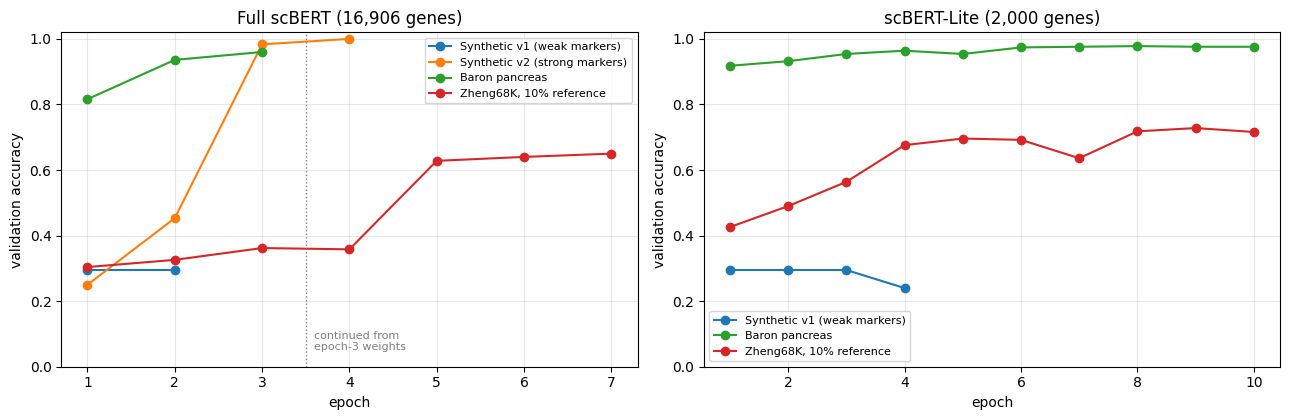

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.3))
COL = dict(zip(EXPS, ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']))
for exp, label in EXPS.items():
    if exp == 'zheng_ref10':
        lg = []
        for n in ['scBERT, 3 epochs', 'scBERT, 7 epochs']:
            if (exp, n) in M: lg += M[(exp, n)]['log']
        if lg:
            axs[0].plot(range(1, len(lg) + 1), [l['val_acc'] for l in lg], marker='o', label=label, color=COL[exp])
            axs[0].axvline(3.5, color='grey', ls=':', lw=1)
            axs[0].text(3.6, 0.05, 'continued from\nepoch-3 weights', fontsize=8, color='grey')
    elif (exp, 'scBERT') in M:
        lg = M[(exp, 'scBERT')]['log']; axs[0].plot([l['epoch'] for l in lg], [l['val_acc'] for l in lg], marker='o', label=label, color=COL[exp])
    if (exp, 'scBERT-Lite (2,000 genes)') in M:
        lg = M[(exp, 'scBERT-Lite (2,000 genes)')]['log']
        axs[1].plot([l['epoch'] for l in lg], [l['val_acc'] for l in lg], marker='o', label=label, color=COL[exp])
axs[0].set_title('Full scBERT (16,906 genes)'); axs[1].set_title('scBERT-Lite (2,000 genes)')
for ax in axs:
    ax.set_xlabel('epoch'); ax.set_ylabel('validation accuracy'); ax.set_ylim(0, 1.02); ax.grid(alpha=.3); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(f'{OUT}/all_training_curves.png', dpi=200); plt.show()

## A3. Accuracy and macro F1 by model

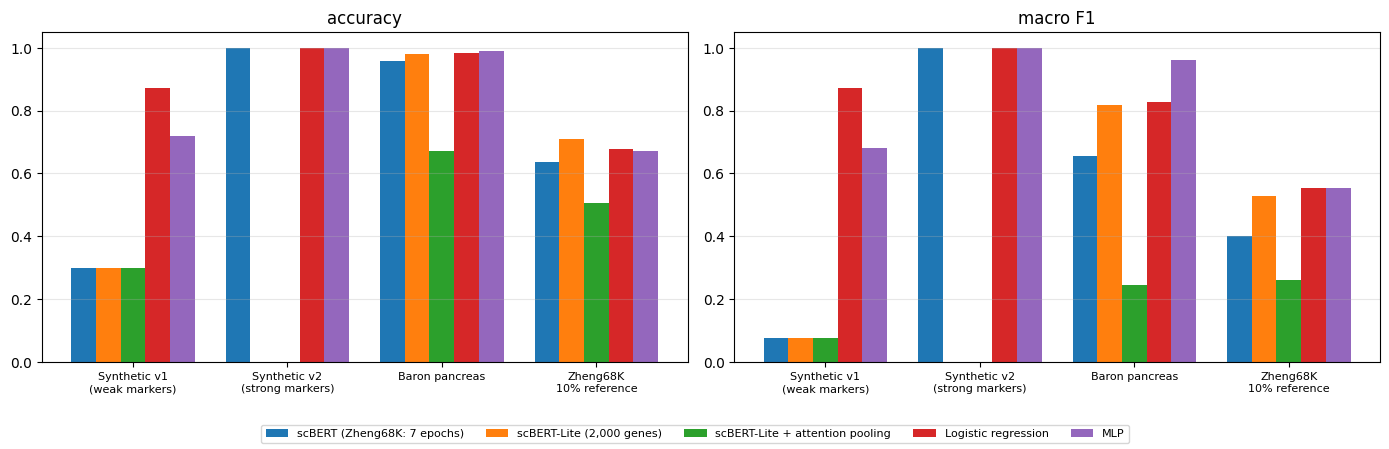

In [4]:
order = ['scBERT', 'scBERT-Lite (2,000 genes)', 'scBERT-Lite + attention pooling', 'Logistic regression', 'MLP']
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, metric in zip(axs, ['accuracy', 'macro F1']):
    for k, mo in enumerate(order):
        names = [mo, 'scBERT, 7 epochs'] if mo == 'scBERT' else [mo]
        vals = []
        for exp, label in EXPS.items():
            sel = MAIN[(MAIN.experiment == label) & (MAIN.model.isin(names))]
            vals.append(sel[metric].iloc[-1] if len(sel) else np.nan)
        ax.bar(np.arange(len(EXPS)) + (k - 2) * 0.16, np.nan_to_num(vals), 0.16,
               label='scBERT (Zheng68K: 7 epochs)' if mo == 'scBERT' else mo)
    ax.set_xticks(range(len(EXPS))); ax.set_xticklabels([v.replace(' (', '\n(').replace(', ', '\n') for v in EXPS.values()], fontsize=8)
    ax.set_ylim(0, 1.05); ax.set_title(metric); ax.grid(axis='y', alpha=.3)
h, l = axs[0].get_legend_handles_labels()
fig.legend(h, l, loc='lower center', ncol=5, fontsize=8); fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.savefig(f'{OUT}/all_bars.png', dpi=200); plt.show()

## A4. Per-class F1 (where each model succeeds or fails, e.g. rare cell types)

In [5]:
for exp, label in EXPS.items():
    ms = {n: m for (e, n), m in M.items() if e == exp}
    if not ms: continue
    any_m = next(iter(ms.values())); L = any_m['labels']
    pc = pd.DataFrame({n: [m['per_class'][c]['f1-score'] for c in L] for n, m in ms.items()}, index=L)
    pc.insert(0, 'test cells', [int(any_m['per_class'][c]['support']) for c in L])
    display(Markdown(f'**{label}**')); display(pc.sort_values('test cells', ascending=False).round(3))

**Synthetic v1 (weak markers)**

,test cells,scBERT,"scBERT-Lite (2,000 genes)",scBERT-Lite + attention pooling,Logistic regression,MLP
type_A,179,0.46,0.46,0.46,0.829,0.678
type_B,140,0.00,0.00,0.00,0.816,0.652
type_C,110,0.00,0.00,0.00,0.991,0.914
type_D,82,0.00,0.00,0.00,0.952,0.841
type_E,50,0.00,0.00,0.00,0.709,0.241
type_F,39,0.00,0.00,0.00,0.932,0.756


**Synthetic v2 (strong markers)**

,test cells,scBERT,Logistic regression,MLP
type_A,170,1.0,1.0,1.0
type_B,150,1.0,1.0,1.0
type_C,112,1.0,1.0,1.0
type_D,78,1.0,1.0,1.0
type_E,55,1.0,1.0,1.0
type_F,35,1.0,1.0,1.0


**Baron pancreas**

,test cells,scBERT,"scBERT-Lite (2,000 genes)",scBERT-Lite + attention pooling,Logistic regression,MLP
beta,505,0.984,0.990,0.736,0.991,0.994
alpha,465,0.980,0.986,0.718,0.989,0.993
ductal,215,0.960,0.984,0.675,0.988,0.993
acinar,192,0.956,0.981,0.910,0.987,0.987
delta,120,0.946,0.967,0.000,0.971,0.975
activated_stellate,57,0.908,0.966,0.000,0.982,0.982
gamma,51,0.854,0.990,0.000,1.000,1.000
endothelial,50,0.911,0.980,0.385,0.969,0.980
quiescent_stellate,35,0.758,0.882,0.000,0.848,0.866
macrophage,11,0.900,0.909,0.000,0.952,1.000


**Zheng68K, 10% reference**

,test cells,"scBERT, 3 epochs","scBERT, 7 epochs","scBERT-Lite (2,000 genes)",scBERT-Lite + attention pooling,Logistic regression,MLP
CD8+ Cytotoxic T,2426,0.482,0.626,0.745,0.506,0.685,0.672
CD8+/CD45RA+ Naive Cytotoxic,1945,0.306,0.672,0.708,0.638,0.665,0.658
CD56+ NK,1026,0.000,0.850,0.900,0.613,0.895,0.899
CD4+/CD25 T Reg,723,0.000,0.085,0.507,0.000,0.474,0.476
CD19+ B,687,0.000,0.773,0.782,0.060,0.777,0.743
CD4+/CD45RO+ Memory,357,0.000,0.000,0.000,0.000,0.246,0.226
CD14+ Monocyte,333,0.000,0.757,0.852,0.646,0.850,0.857
Dendritic,245,0.000,0.663,0.685,0.426,0.688,0.708
CD4+/CD45RA+/CD25- Naive T,219,0.000,0.000,0.000,0.000,0.043,0.033
CD34+,28,0.000,0.000,0.634,0.000,0.756,0.809


## A5. Confusion matrices (row-normalized: each row = the true cell type)

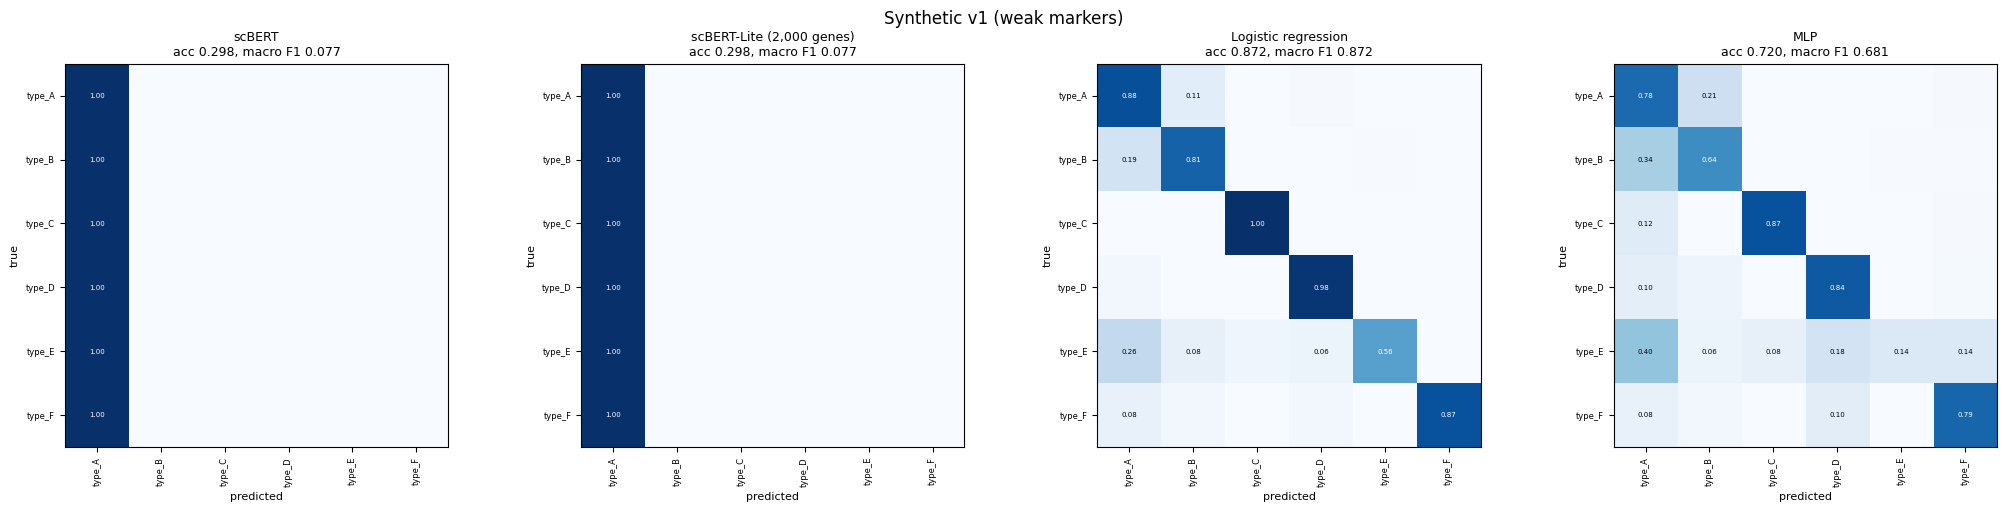

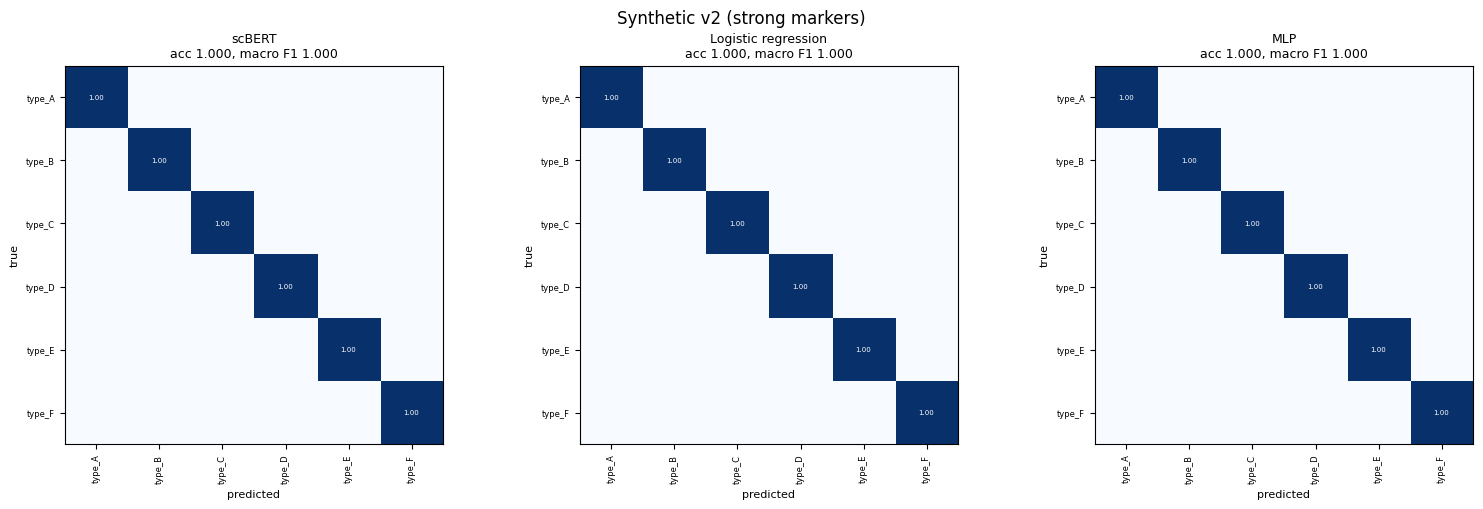

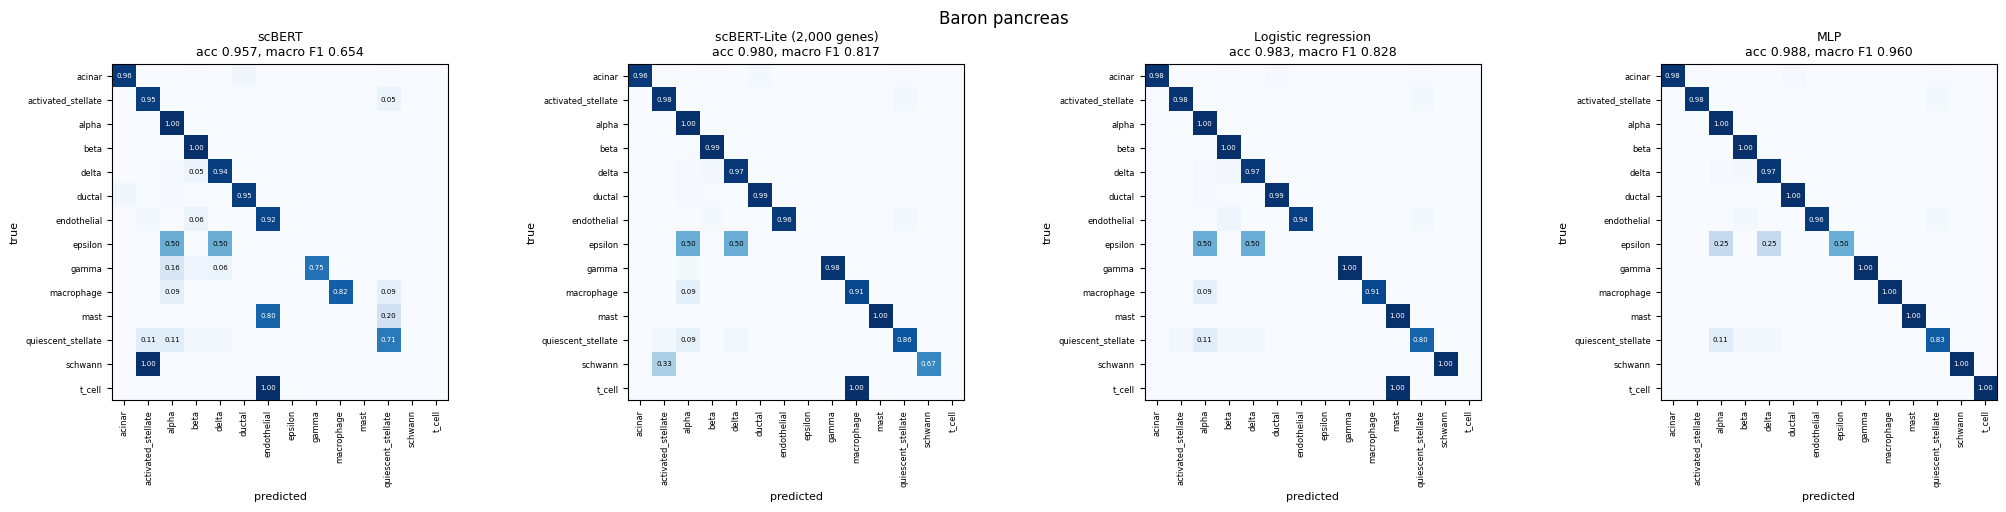

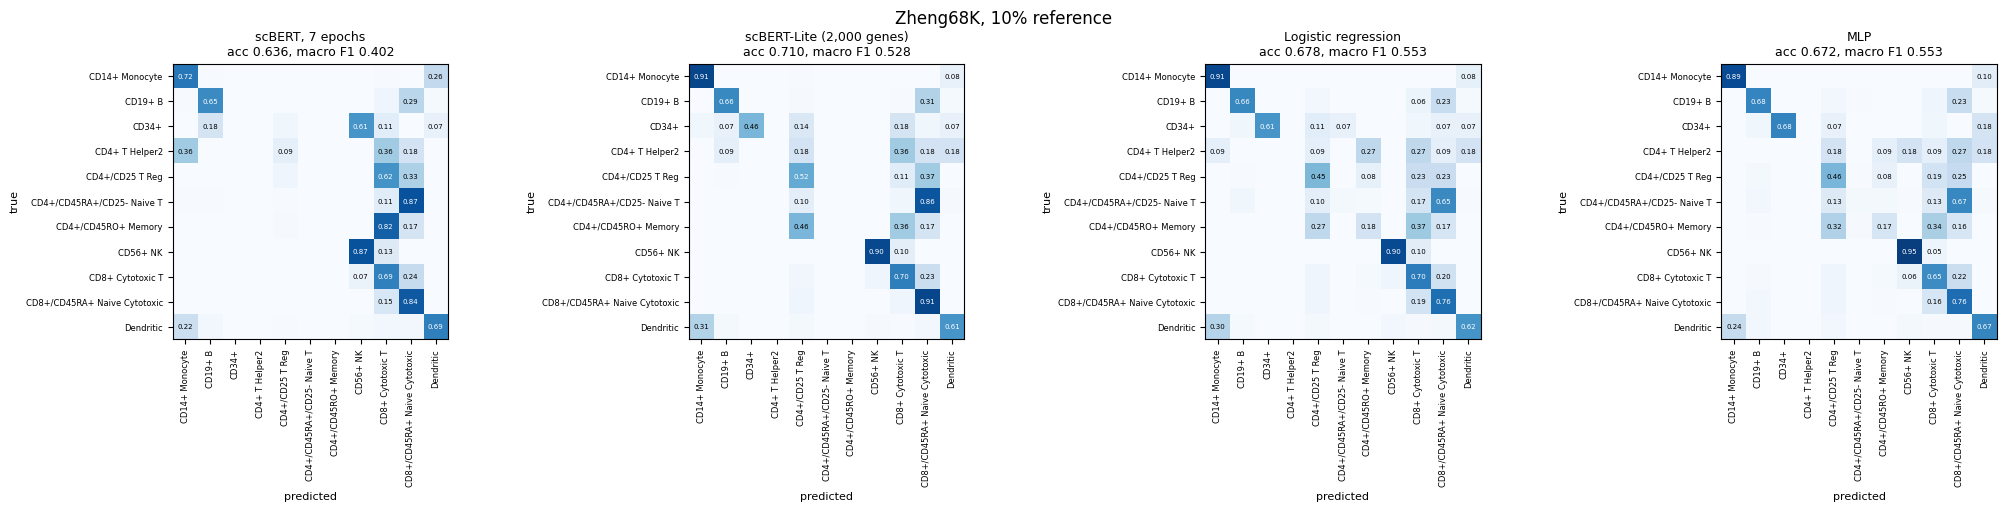

In [6]:
def draw_cms(exp, names):
    ms = [(n, M[(exp, n)]) for n in names if (exp, n) in M]
    if not ms: return
    fig, axs = plt.subplots(1, len(ms), figsize=(5.2 * len(ms), 5), squeeze=False)
    for ax, (n, m) in zip(axs[0], ms):
        cm = np.array(m['confusion_matrix'], float); cmn = cm / cm.sum(1, keepdims=True).clip(min=1); L = m['labels']
        ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
        ax.set_xticks(range(len(L))); ax.set_xticklabels(L, rotation=90, fontsize=6)
        ax.set_yticks(range(len(L))); ax.set_yticklabels(L, fontsize=6)
        for i in range(len(L)):
            for j in range(len(L)):
                if cmn[i, j] >= .05: ax.text(j, i, f'{cmn[i, j]:.2f}', ha='center', va='center', fontsize=5, color='white' if cmn[i, j] > .5 else 'black')
        ax.set_title(f'{n}\nacc {m["test_accuracy"]:.3f}, macro F1 {m["test_macro_f1"]:.3f}', fontsize=9)
        ax.set_xlabel('predicted', fontsize=8); ax.set_ylabel('true', fontsize=8)
    fig.suptitle(EXPS[exp]); fig.tight_layout(); fig.savefig(f'{OUT}/cm_{exp}.png', dpi=200); plt.show()

for exp in EXPS:
    draw_cms(exp, ['scBERT', 'scBERT, 7 epochs', 'scBERT-Lite (2,000 genes)', 'Logistic regression', 'MLP'])

## A6. Novelty C: binning ablation (baselines given scBERT's integer 0–5 input instead of continuous values)

In [7]:
p = f'{NOV}/binning_ablation.csv'
if os.path.exists(p):
    display(pd.read_csv(p).round(4))
else:
    print('binning_ablation.csv not found (run Component 4, cell C)')

,experiment,model,acc continuous,acc binned,Δ acc,F1 continuous,F1 binned,Δ F1
0,synthetic_holdout,logreg,0.8717,0.8883,0.0167,0.8715,0.8822,0.0107
1,synthetic_holdout,mlp,0.7200,0.7600,0.0400,0.6806,0.7364,0.0559
2,baron_holdout,logreg,0.9831,0.9842,0.0012,0.8277,0.9074,0.0797
3,baron_holdout,mlp,0.9877,0.9837,-0.0041,0.9597,0.8825,-0.0772
4,zheng_ref10,logreg,0.6782,0.6780,-0.0002,0.5525,0.5509,-0.0016
5,zheng_ref10,mlp,0.6718,0.6828,0.0110,0.5528,0.5541,0.0013


# Part B: live re-scoring of the saved models (L4 GPU)
Each cell loads a saved `best.pt`, predicts the saved test cells and compares every prediction with the one saved
during training. Full scBERT reads all 16,906 genes per cell (~6 cells/s), so it scores a 300-cell stratified sample.

In [8]:
os.chdir('/content'); REPO = '/content/scBERT'
!pip -q install local-attention einops scanpy anndata "pandas==2.2.3"
if not os.path.exists(REPO):
    !git clone -q https://github.com/TencentAILabHealthcare/scBERT.git {REPO}

In [9]:
%%writefile evaluate.py
import os, sys, json, time, argparse
import numpy as np, pandas as pd, scanpy as sc, torch
from torch import nn
from scipy import sparse
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix)

p = argparse.ArgumentParser()
p.add_argument('--run_dir', required=True, help='folder holding best.pt + test_predictions.csv (+ split.npz)')
p.add_argument('--data', required=True, help='the preprocessed .h5ad the run used')
p.add_argument('--split', default=None, help="split.npz (default: <run_dir>/split.npz, or the scBERT run's)")
p.add_argument('--repo', default='/content/scBERT')
p.add_argument('--n_cells', type=int, default=0, help='stratified sample of test cells to score (0 = all)')
p.add_argument('--batch_size', type=int, default=0, help='0 = same eval batch size as the training run')
p.add_argument('--no_amp', action='store_true', help='force float32 (default: same precision as the training run)')
p.add_argument('--seed', type=int, default=0)
args = p.parse_args()

CLASS, N_ALL = 7, 16906
dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
sys.path.insert(0, args.repo)
import performer_pytorch.performer_pytorch as pp
def _g2v_init(self, dim, max_seq_len):
    nn.Module.__init__(self); self.emb = nn.Embedding(max_seq_len, dim); self.emb.weight.requires_grad_(False)
pp.Gene2VecPositionalEmbedding.__init__ = _g2v_init
def _orth_chunk(cols, device=None):
    q, _ = torch.linalg.qr(torch.randn((cols, cols)), mode='reduced'); return q.t().to(device)
pp.orthogonal_matrix_chunk = _orth_chunk
from performer_pytorch import PerformerLM

lite = os.path.exists(os.path.join(args.run_dir, 'genes_used.npy'))
meta = json.load(open(os.path.join(args.run_dir, 'metrics.json')))
head = meta.get('head', 'conv') if lite else 'conv'
BS = args.batch_size or int(meta['args'].get('eval_bs', 8))
AMP = bool(meta['args'].get('amp', False)) and not args.no_amp
if AMP and dev.type == 'cuda' and torch.cuda.get_device_capability()[0] < 8:
    AMP = False
    print('note: this GPU has no native bfloat16, so scoring in float32; a few borderline cells may differ from the saved predictions')
if AMP and dev.type != 'cuda':
    AMP = False

A = sc.read_h5ad(args.data)
X = (A.X.tocsr() if sparse.issparse(A.X) else sparse.csr_matrix(A.X)).astype(np.float32)
names, y = np.unique(np.asarray(A.obs['celltype']).astype(str), return_inverse=True)
if lite:
    genes = np.load(os.path.join(args.run_dir, 'genes_used.npy'), allow_pickle=True)
    pos = pd.Index(A.var_names).get_indexer(genes); assert (pos >= 0).all()
    X = X[:, np.sort(pos)].tocsr()
SEQ = X.shape[1] + 1

split_p = args.split or (os.path.join(args.run_dir, 'split.npz') if os.path.exists(os.path.join(args.run_dir, 'split.npz'))
                         else meta['args']['split_from'])
test = np.load(split_p)['test']
if args.n_cells and args.n_cells < len(test):
    try:
        test, _ = train_test_split(test, train_size=args.n_cells, stratify=y[test], random_state=args.seed)
    except ValueError:
        test, _ = train_test_split(test, train_size=args.n_cells, random_state=args.seed)

class Conv(nn.Module):
    def __init__(self, n):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 1, (1, 200)); self.act = nn.ReLU()
        self.fc1 = nn.Linear(SEQ, 512); self.act1 = nn.ReLU(); self.dropout1 = nn.Dropout(0.)
        self.fc2 = nn.Linear(512, 128); self.act2 = nn.ReLU(); self.dropout2 = nn.Dropout(0.)
        self.fc3 = nn.Linear(128, n)
    def forward(self, x):
        x = self.act(self.conv1(x[:, None])).view(x.shape[0], -1)
        return self.fc3(self.dropout2(self.act2(self.fc2(self.dropout1(self.act1(self.fc1(x)))))))
class Pool(nn.Module):
    def __init__(self, n):
        super().__init__()
        self.score = nn.Linear(200, 1)
        self.mlp = nn.Sequential(nn.LayerNorm(200), nn.Linear(200, 128), nn.ReLU(), nn.Dropout(0.1), nn.Linear(128, n))
    def forward(self, x):
        w = torch.softmax(self.score(x).squeeze(-1), dim=1); return self.mlp((w.unsqueeze(-1) * x).sum(1))

model = PerformerLM(num_tokens=CLASS, dim=200, depth=6, max_seq_len=SEQ, heads=10, local_attn_heads=0, g2v_position_emb=True)
model.to_out = Pool(len(names)) if head == 'pool' else Conv(len(names))
sd = torch.load(os.path.join(args.run_dir, 'best.pt'), map_location='cpu', weights_only=True)
model.load_state_dict(sd, strict=True); model.to(dev).eval()
print(f'model: {"scBERT-Lite" if lite else "full scBERT"} ({SEQ - 1} genes, {head} head) | scoring {len(test)} test cells on {dev}')

t0 = time.time(); preds = []
with torch.no_grad():
    for i in range(0, len(test), BS):
        rows = X[test[i:i + BS]].toarray(); rows[rows > CLASS - 2] = CLASS - 2
        seq = torch.cat((torch.from_numpy(rows).long(), torch.zeros((len(rows), 1), dtype=torch.long)), 1).to(dev)
        with torch.autocast('cuda', dtype=torch.bfloat16, enabled=AMP and dev.type == 'cuda'):
            preds.append(model(seq).float().argmax(1).cpu().numpy())
pred = np.concatenate(preds); yt = y[test]; secs = time.time() - t0

print(f'\nscored {len(test)} cells in {secs:.1f} s ({secs / len(test):.3f} s/cell)')
print(f'accuracy {accuracy_score(yt, pred):.4f}  macro P {precision_score(yt, pred, average="macro", zero_division=0):.4f}  '
      f'macro R {recall_score(yt, pred, average="macro", zero_division=0):.4f}  macro F1 {f1_score(yt, pred, average="macro", zero_division=0):.4f}')
present = np.union1d(yt, pred)
print(classification_report(yt, pred, labels=present, target_names=names[present], digits=4, zero_division=0))

saved = pd.read_csv(os.path.join(args.run_dir, 'test_predictions.csv')).set_index('cell')
cells = A.obs_names[test]
same = (saved.loc[cells, 'pred'].values == names[pred])
print(f'predictions identical to the saved training-run predictions: {same.sum()} / {len(same)} cells ({same.mean():.1%})')
if len(test) == len(np.load(split_p)['test']):
    print(f'saved metrics for the full test set: accuracy {meta["test_accuracy"]:.4f}, macro F1 {meta["test_macro_f1"]:.4f}')

Writing evaluate.py


## B1. Full scBERT, Baron (300 random test cells, ~1 min)

In [10]:
!python evaluate.py --run_dir "{RES}/baron_holdout/fold0" --data "{DATA}/baron_scbert.h5ad" --repo "{REPO}" --n_cells 300

model: full scBERT (16906 genes, conv head) | scoring 300 test cells on cuda

scored 300 cells in 47.2 s (0.157 s/cell)
accuracy 0.9567  macro P 0.7110  macro R 0.7077  macro F1 0.7054
                    precision    recall  f1-score   support

            acinar     0.8889    0.9697    0.9275        33
activated_stellate     1.0000    1.0000    1.0000         6
             alpha     0.9647    1.0000    0.9820        82
              beta     0.9886    0.9886    0.9886        88
             delta     0.9130    0.9545    0.9333        22
            ductal     0.9767    0.9130    0.9438        46
       endothelial     0.8000    1.0000    0.8889         8
           epsilon     0.0000    0.0000    0.0000         1
             gamma     1.0000    0.6667    0.8000         9
              mast     0.0000    0.0000    0.0000         1
quiescent_stellate     1.0000    1.0000    1.0000         3
            t_cell     0.0000    0.0000    0.0000         1

          accuracy               

## B2. Full scBERT after 7 epochs, Zheng68K 10% reference (300 random test cells, ~1 min)

In [11]:
!python evaluate.py --run_dir "{RES}/zheng_ref10_cont/fold0" --data "{DATA}/zheng68k_scbert.h5ad" --repo "{REPO}" --n_cells 300

model: full scBERT (16906 genes, conv head) | scoring 300 test cells on cuda

scored 300 cells in 46.9 s (0.156 s/cell)
accuracy 0.6767  macro P 0.5812  macro R 0.4960  macro F1 0.4926
                              precision    recall  f1-score   support

              CD14+ Monocyte     0.9167    0.8462    0.8800        13
                     CD19+ B     0.9444    0.6538    0.7727        26
                       CD34+     0.0000    0.0000    0.0000         1
             CD4+/CD25 T Reg     1.0000    0.0741    0.1379        27
  CD4+/CD45RA+/CD25- Naive T     0.0000    0.0000    0.0000         8
         CD4+/CD45RO+ Memory     0.0000    0.0000    0.0000        13
                    CD56+ NK     0.8750    0.8974    0.8861        39
            CD8+ Cytotoxic T     0.5929    0.7363    0.6569        91
CD8+/CD45RA+ Naive Cytotoxic     0.5943    0.8630    0.7039        73
                   Dendritic     0.8889    0.8889    0.8889         9

                    accuracy               

## B3. scBERT-Lite (novelty A), Baron (all 1,714 test cells)

In [12]:
!python evaluate.py --run_dir "{NOV}/baron_holdout/lite2000_conv" --data "{DATA}/baron_scbert.h5ad" --repo "{REPO}"

model: scBERT-Lite (2000 genes, conv head) | scoring 1714 test cells on cuda

scored 1714 cells in 31.8 s (0.019 s/cell)
accuracy 0.9802  macro P 0.8340  macro R 0.8046  macro F1 0.8168
                    precision    recall  f1-score   support

            acinar     1.0000    0.9635    0.9814       192
activated_stellate     0.9492    0.9825    0.9655        57
             alpha     0.9748    0.9978    0.9862       465
              beta     0.9862    0.9941    0.9901       505
             delta     0.9667    0.9667    0.9667       120
            ductal     0.9815    0.9860    0.9838       215
       endothelial     1.0000    0.9600    0.9796        50
           epsilon     0.0000    0.0000    0.0000         4
             gamma     1.0000    0.9804    0.9901        51
        macrophage     0.9091    0.9091    0.9091        11
              mast     1.0000    1.0000    1.0000         5
quiescent_stellate     0.9091    0.8571    0.8824        35
           schwann     1.0000    

## B4. scBERT-Lite (novelty A), Zheng68K (all 8,000 test cells, ~2.5 min)

In [13]:
!python evaluate.py --run_dir "{NOV}/zheng_ref10/lite2000_conv" --data "{DATA}/zheng68k_scbert.h5ad" --repo "{REPO}"

model: scBERT-Lite (2000 genes, conv head) | scoring 8000 test cells on cuda

scored 8000 cells in 147.2 s (0.018 s/cell)
accuracy 0.7096  macro P 0.5748  macro R 0.5153  macro F1 0.5284
                              precision    recall  f1-score   support

              CD14+ Monocyte     0.7979    0.9129    0.8515       333
                     CD19+ B     0.9657    0.6565    0.7816       687
                       CD34+     1.0000    0.4643    0.6341        28
              CD4+ T Helper2     0.0000    0.0000    0.0000        11
             CD4+/CD25 T Reg     0.4993    0.5159    0.5075       723
  CD4+/CD45RA+/CD25- Naive T     0.0000    0.0000    0.0000       219
         CD4+/CD45RO+ Memory     0.0000    0.0000    0.0000       357
                    CD56+ NK     0.8958    0.9045    0.9001      1026
            CD8+ Cytotoxic T     0.8011    0.6958    0.7448      2426
CD8+/CD45RA+ Naive Cytotoxic     0.5789    0.9105    0.7078      1945
                   Dendritic     0.7842   

## B5. Baseline: retrain logistic regression on Baron with its saved C (~1 min, CPU) and compare

In [14]:
import scanpy as sc
from scipy import sparse
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
ad = sc.read_h5ad(f'{DATA}/baron_scbert.h5ad'); X = sparse.csr_matrix(ad.X).astype(np.float32)
names, y = np.unique(np.asarray(ad.obs['celltype']).astype(str), return_inverse=True)
s = np.load(f'{RES}/baron_holdout/fold0/split.npz'); fit, test = s['fit'], s['test']
C = json.load(open(f'{BENCH}/baron_holdout/logreg/metrics.json'))['C']
pred = LogisticRegression(C=C, max_iter=1000, tol=1e-4).fit(X[fit], y[fit]).predict(X[test])
saved = pd.read_csv(f'{BENCH}/baron_holdout/logreg/test_predictions.csv')
print(f'logreg (C={C}): accuracy {accuracy_score(y[test], pred):.4f}, macro F1 {f1_score(y[test], pred, average="macro"):.4f}')
print(f'identical to saved predictions: {(saved["pred"].values == names[pred]).mean():.1%}')

logreg (C=0.1): accuracy 0.9831, macro F1 0.8277
identical to saved predictions: 100.0%
